# Project A INAIL 1 TDF and MATLAB timing audit V3
Run all cells. This standalone notebook scans original TDF files and MATLAB exports, checks nominal clock metadata and source correspondence, reconciles event annotations, and measures constant/missing signal runs inside candidate lifting intervals. It exports a ZIP under Project_A/archives and tables/figures under Project_A/results/INAIL1_TDF_V3.

Dependencies: numpy, pandas, scipy, matplotlib. No basictdf installation is needed. The bounded reader implements the observed BTS version-1 directory and by-track marker/EMG/event layouts. Unsupported formats are recorded as failures rather than guessed. Declared sample counts and segment offsets are preserved exactly; no arbitrary 49-sample adjustment is applied.

Two candidate phases are inspected separately: MATLAB one-based start/stop indices and original TDF Start/Stop annotations. Neither is selected by prediction accuracy or EMG activation. A shared nominal time origin is metadata evidence, not proof of hardware synchronization accuracy. All phase measurements remain diagnostic candidates until the inference contract and endpoint are fixed. No models are trained and no source files are modified.

Parser references: https://marnunez.github.io/basictdf/basictdf/tdfData3D.html and https://marnunez.github.io/basictdf/basictdf/tdfEMG.html and https://marnunez.github.io/basictdf/basictdf/tdfEvents.html. This reader checks block boundaries and uses the EMG sample count declared in the header. It supports only the layouts explicitly checked here. Code cells contain no comments.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
from collections import defaultdict
import hashlib
import io
import struct
import json
import re
import sys
import traceback
import zipfile
import numpy as np
import pandas as pd
from scipy.io import loadmat
from scipy.signal import butter, sosfiltfilt
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = Path("/home/rafsan/Documents/GitHub/IPEXBIO/Project_A")
DATA_ROOT = Path.home() / "Downloads/INAIL_1/Dataset1/DATA"
MAX_FIGURES = 10
MARKER_RMSE_REVIEW_LIMIT = 0.005
MARKER_MAX_ERROR_REVIEW_LIMIT = 0.02
CONSTANT_RUN_REVIEW_SECONDS = 0.05
EXPECTED_EMG = ["RESL", "RESI", "RM", "RLD", "RRAS", "RRAM", "REO", "RIO", "LESL", "LESI", "LM", "LLD", "LRAS", "LRAM", "LEO", "LIO"]

PROJECT_ROOT = PROJECT_ROOT.expanduser().resolve()
DATA_ROOT = DATA_ROOT.expanduser().resolve()
if not DATA_ROOT.is_dir():
    raise FileNotFoundError(f"Edit DATA_ROOT to the existing raw DATA directory: {DATA_ROOT}")
RUN_DIR = PROJECT_ROOT / "results" / "INAIL1_TDF_V3" / datetime.now(timezone.utc).strftime("run_%Y%m%dT%H%M%S_%fZ")
RUN_DIR.mkdir(parents=True,exist_ok=False)
FIG_DIR=RUN_DIR/"figures"
FIG_DIR.mkdir()
print("Project:",PROJECT_ROOT)
print("Raw data:",DATA_ROOT)
print("Results:",RUN_DIR)
pd.set_option("display.max_columns",35)
pd.set_option("display.max_rows",30)

Project: /home/rafsan/Documents/GitHub/IPEXBIO/Project_A
Raw data: /home/rafsan/Downloads/INAIL_1/Dataset1/DATA
Results: /home/rafsan/Documents/GitHub/IPEXBIO/Project_A/results/INAIL1_TDF_V3/run_20261113T055107_741782Z


## Bounded TDF binary reader

In [2]:
class Reader:
    def __init__(self,data):
        self.data=memoryview(data)
        self.pos=0
    def take(self,n):
        if n<0 or self.pos+n>len(self.data):
            raise ValueError(f"Read outside block at {self.pos}, length {n}, block bytes {len(self.data)}")
        out=self.data[self.pos:self.pos+n]
        self.pos+=n
        return out
    def unpack(self,fmt):
        return struct.unpack(fmt,self.take(struct.calcsize(fmt)))
    def integer(self):
        return self.unpack("<i")[0]
    def string(self,n):
        return bytes(self.take(n)).split(b"\x00")[0].decode("cp1252",errors="replace")
    def count(self,max_value=10000000):
        v=self.integer()
        if not 0<=v<=max_value:
            raise ValueError(f"Invalid count {v}")
        return v
    def finish(self):
        if self.pos!=len(self.data):
            raise ValueError(f"Unconsumed block bytes: {len(self.data)-self.pos}")

def parse_tracks(r,count,n_samples,dimensions):
    if count*n_samples*dimensions>100000000:
        raise ValueError("Requested allocation exceeds audit limit")
    tracks=[]
    for j in range(count):
        label=r.string(256)
        nseg=r.count(10000)
        r.take(4)
        segments=[r.unpack("<ii") for _ in range(nseg)]
        a=np.full((n_samples,dimensions),np.nan,dtype=np.float32)
        end=0
        for start,length in segments:
            if start<0 or length<0 or start+length>n_samples or start<end:
                raise ValueError(f"Invalid or overlapping segment {start,length}")
            a[start:start+length]=np.frombuffer(r.take(length*dimensions*4),dtype="<f4").reshape(length,dimensions)
            end=start+length
        tracks.append({"label":label,"segments":segments,"data":a[:,0] if dimensions==1 else a})
    return tracks

def parse_tdf(path):
    payload=path.read_bytes()
    if payload[:16]!=bytes.fromhex("824b6041d31184ca6000b6ac16680c08"):
        raise ValueError("Unrecognized TDF signature")
    if len(payload)<64:
        raise ValueError("Truncated TDF header")
    version,n=struct.unpack_from("<Ii",payload,16)
    if version!=1 or not 0<n<=1000 or 64+n*288>len(payload):
        raise ValueError("Unsupported TDF version or directory")
    entries=[]
    blocks={}
    ranges=[]
    for j in range(n):
        kind,fmt,offset,size=struct.unpack_from("<IIii",payload,64+j*288)
        if not size:
            continue
        if offset<64+n*288 or size<0 or offset+size>len(payload):
            raise ValueError("Invalid block boundary")
        ranges.append((offset,offset+size))
        entries.append({"type":kind,"format":fmt,"offset":offset,"bytes":size})
        if kind not in [5,11,16]:
            continue
        if kind in blocks:
            raise ValueError("Multiple blocks of a required type")
        r=Reader(payload[offset:offset+size])
        if kind==5:
            if fmt not in [1,2]:
                raise ValueError(f"Unsupported marker format {fmt}")
            frames=r.count()
            frequency=r.integer()
            start=r.unpack("<f")[0]
            tracks=r.count(1000)
            volume=np.frombuffer(r.take(12),dtype="<f4").tolist()
            rotation=np.frombuffer(r.take(36),dtype="<f4").reshape(3,3).tolist()
            translation=np.frombuffer(r.take(12),dtype="<f4").tolist()
            flag=r.unpack("<I")[0]
            if fmt==1:
                links=r.count(100000)
                r.take(4+links*8)
            block={"frequency":frequency,"start":start,"count":frames,"flag":flag,"volume":volume,"rotation":rotation,"translation":translation,"tracks":parse_tracks(r,tracks,frames,3)}
        elif kind==11:
            if fmt!=1:
                raise ValueError(f"Unsupported EMG format {fmt}")
            signals=r.count(1000)
            frequency=r.integer()
            start=r.unpack("<f")[0]
            samples=r.count()
            channel_map=np.frombuffer(r.take(signals*2),dtype="<i2").tolist()
            block={"frequency":frequency,"start":start,"count":samples,"channel_map":channel_map,"tracks":parse_tracks(r,signals,samples,1)}
        else:
            if fmt!=1:
                raise ValueError(f"Unsupported event format {fmt}")
            events=r.count(10000)
            start=r.unpack("<f")[0]
            values=[]
            for _ in range(events):
                label=r.string(256)
                event_type=r.unpack("<I")[0]
                length=r.count(100000)
                array=np.frombuffer(r.take(length*4),dtype="<f4").astype(float)
                values.append({"label":label,"type":event_type,"values":array.tolist()})
            block={"start":start,"events":values}
        r.finish()
        if kind in [5,11] and (block["frequency"]<=0 or not np.isfinite(block["start"])):
            raise ValueError("Invalid stream clock header")
        blocks[kind]=block
    ranges.sort()
    if any(a[1]>b[0] for a,b in zip(ranges,ranges[1:])):
        raise ValueError("Overlapping block ranges")
    return {"version":version,"entries":entries,"blocks":blocks,"sha256":hashlib.sha256(payload).hexdigest()}

## MATLAB and signal utilities

In [3]:
def entries(value):
    if isinstance(value, dict):
        return [value]
    if isinstance(value, (list, tuple)):
        return list(value)
    if isinstance(value, np.ndarray):
        return list(value.reshape(-1))
    return []

def numeric(value):
    a = np.asarray(value)
    return a if a.dtype.kind in "biufc" else None

def leaves(value, prefix=""):
    if isinstance(value, dict):
        for key, item in value.items():
            yield from leaves(item, f"{prefix}.{key}" if prefix else key)
    else:
        a = numeric(value)
        if a is not None:
            yield prefix, a

def digest(value):
    h = hashlib.sha256()
    count = 0
    for name, a in sorted(leaves(value)):
        h.update(name.encode())
        h.update(str(a.shape).encode())
        h.update(a.dtype.str.encode())
        h.update(np.ascontiguousarray(a).tobytes())
        count += a.size
    return h.hexdigest() if count else None

def scalar(value):
    try:
        a = np.asarray(value)
        return float(a.reshape(-1)[0]) if a.size == 1 else np.nan
    except Exception:
        return np.nan

def rate(value):
    r = scalar(value)
    return r if np.isfinite(r) and r > 0 else np.nan

def longest_run(mask):
    padded = np.r_[False, np.asarray(mask, dtype=bool).reshape(-1), False]
    edges = np.flatnonzero(padded[1:] != padded[:-1])
    return int(np.max(edges[1::2] - edges[::2])) if edges.size else 0

def quality(a, fs):
    a = np.asarray(a)
    values = np.real(a).astype(float)
    flat = values.reshape(-1)
    good = flat[np.isfinite(flat)]
    row_bad = ~np.isfinite(values) if values.ndim <= 1 else ~np.isfinite(values).reshape(values.shape[0], -1).all(axis=1)
    result = {"shape": str(tuple(a.shape)), "dtype": str(a.dtype), "samples": int(a.shape[0]) if a.ndim else 1, "elements": int(a.size), "nonfinite_fraction": float(1 - len(good) / a.size) if a.size else np.nan, "longest_missing_samples": longest_run(row_bad), "fs": fs}
    result["duration_s"] = result["samples"] / fs if np.isfinite(fs) and a.size else np.nan
    if good.size:
        result.update(minimum=float(np.min(good)), maximum=float(np.max(good)), mean=float(np.mean(good)), std=float(np.std(good)), rms=float(np.sqrt(np.mean(good ** 2))), abs_p95=float(np.percentile(np.abs(good), 95)), extreme_value_fraction=float(np.mean((good == good.min()) | (good == good.max()))))
        if values.ndim == 1 and len(values) > 1:
            valid = np.isfinite(values[:-1]) & np.isfinite(values[1:])
            result["equal_adjacent_fraction"] = float(np.mean(np.diff(values)[valid] == 0)) if valid.any() else np.nan
    return result

def moving_rms_reference(a, fs):
    a = np.asarray(a, dtype=float).reshape(-1)
    if not np.isfinite(fs) or len(a) < 2 or not np.isfinite(a).all():
        return np.nan
    a = a - np.mean(a)
    width = max(1, min(len(a), int(round(0.25 * fs))))
    rms = np.sqrt(np.maximum(0, np.convolve(a ** 2, np.ones(width) / width, mode="valid")))
    return float(np.percentile(rms, 95))

def describe_schema(value, path="root", depth=0):
    if depth > 6:
        return []
    if isinstance(value, dict):
        rows = [{"path": path, "kind": "dict", "detail": list(value)}]
        for key, item in value.items():
            rows.extend(describe_schema(item, f"{path}.{key}", depth+1))
        return rows
    if isinstance(value, (list, tuple)):
        return [{"path": path, "kind": "list", "detail": len(value)}] + (describe_schema(value[0], path + "[0]", depth+1) if value else [])
    if isinstance(value, np.ndarray):
        return [{"path": path, "kind": "array", "detail": {"shape": list(value.shape), "dtype": str(value.dtype)}}]
    return [{"path": path, "kind": type(value).__name__, "detail": str(value)[:200]}]

GROUPS = {"Kinematic_data": ("data_3D", "fs_3D"), "sEMG": ("data_sEMG", "fs_sEMG"), "Ground_forces_and_moments": ("platform_data", "fs_forces"), "MVC": ("MVC_data", "fs_MVC")}

In [4]:
def sid_from(text):
    m=re.search(r"S0*(\d+)",str(text),re.I)
    return f"S{int(m.group(1)):02d}" if m else None

def task_key(text):
    return str(text).lower().removesuffix(".tdf")

def constant_runs(a):
    a=np.asarray(a).reshape(-1)
    if not len(a):
        return []
    breaks=np.r_[0,np.flatnonzero((a[1:]!=a[:-1]) | ~np.isfinite(a[1:]) | ~np.isfinite(a[:-1]))+1,len(a)]
    return [(int(s),int(e),float(a[s])) for s,e in zip(breaks[:-1],breaks[1:]) if e>s and np.isfinite(a[s])]

def phase_stats(a,fs,start,stop):
    a=np.asarray(a,dtype=float).reshape(-1)
    part=a[start:stop]
    finite=np.isfinite(part)
    runs=constant_runs(a)
    longest=max((max(0,min(e,stop)-max(s,start)) for s,e,v in runs),default=0)
    return {"samples":len(part),"finite_fraction":float(finite.mean()) if len(part) else 0.0,"longest_constant_s":longest/fs,"zero_fraction":float(np.mean(part==0)) if len(part) else np.nan,"raw_rms":float(np.sqrt(np.mean(part**2))) if len(part) and finite.all() else np.nan}

def phase_filtered_rms(a,fs,start,stop):
    a=np.asarray(a,dtype=float).reshape(-1)
    if not len(a) or not np.isfinite(a[start:stop]).all():
        return np.nan
    valid=np.isfinite(a)
    lo=start
    hi=stop
    while lo>0 and valid[lo-1]:
        lo-=1
    while hi<len(a) and valid[hi]:
        hi+=1
    if hi-lo<64 or fs<=50:
        return np.nan
    segment=a[lo:hi]-np.mean(a[lo:hi])
    filtered=sosfiltfilt(butter(4,[20,min(450,fs*0.45)],btype="bandpass",fs=fs,output="sos"),segment)
    return float(np.sqrt(np.mean(filtered[start-lo:stop-lo]**2)))

mat_paths=sorted([p for p in DATA_ROOT.rglob("*_all_trials.mat") if "__MACOSX" not in p.parts and not p.name.startswith("._")])
tdf_paths=sorted([p for p in DATA_ROOT.rglob("*") if p.is_file() and p.suffix.lower()==".tdf" and "__MACOSX" not in p.parts and not p.name.startswith("._")])
if not mat_paths or not tdf_paths:
    raise FileNotFoundError("Both MATLAB exports and original TDF files are required")
tdf_index=defaultdict(list)
for path in tdf_paths:
    tdf_index[(sid_from(path.stem),task_key(path.stem))].append(path)
print("MATLAB files:",len(mat_paths),"TDF files:",len(tdf_paths))

MATLAB files: 17 TDF files: 132


## Source comparison and candidate phase inspection
EMG channels are matched by exact sample correspondence after a fixed 10^6 scaling, with a strict roundoff tolerance. A channel mapping is accepted only if it has exactly one matching full-length TDF track. Derived/segmented tracks are retained in the track inventory and are not used as primary signals.

Marker differences are measured at the same sample indices. The engineering review limits below accommodate possible processing differences; they do not certify synchronization. Both zero-based and one-based MATLAB event interpretations are compared with every TDF event. Candidate extraction uses an explicitly labelled one-based MATLAB interpretation and, separately, exact TDF Start/Stop times.

Constant runs of at least 50 ms inside a phase are flagged for review. Exact 49-sample zero tails remain visible in the reports. Filtering does not turn padded samples into valid physiology. Candidate raw-amplitude RMS values are not MVC-normalized outcomes.

[1/17] S01


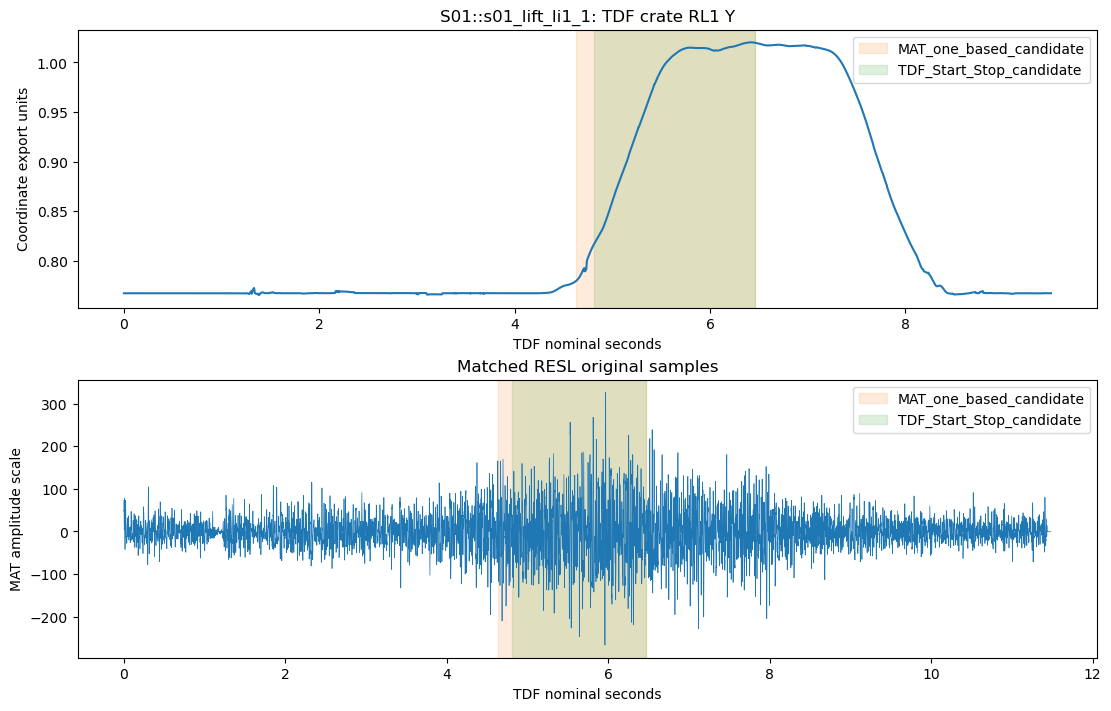

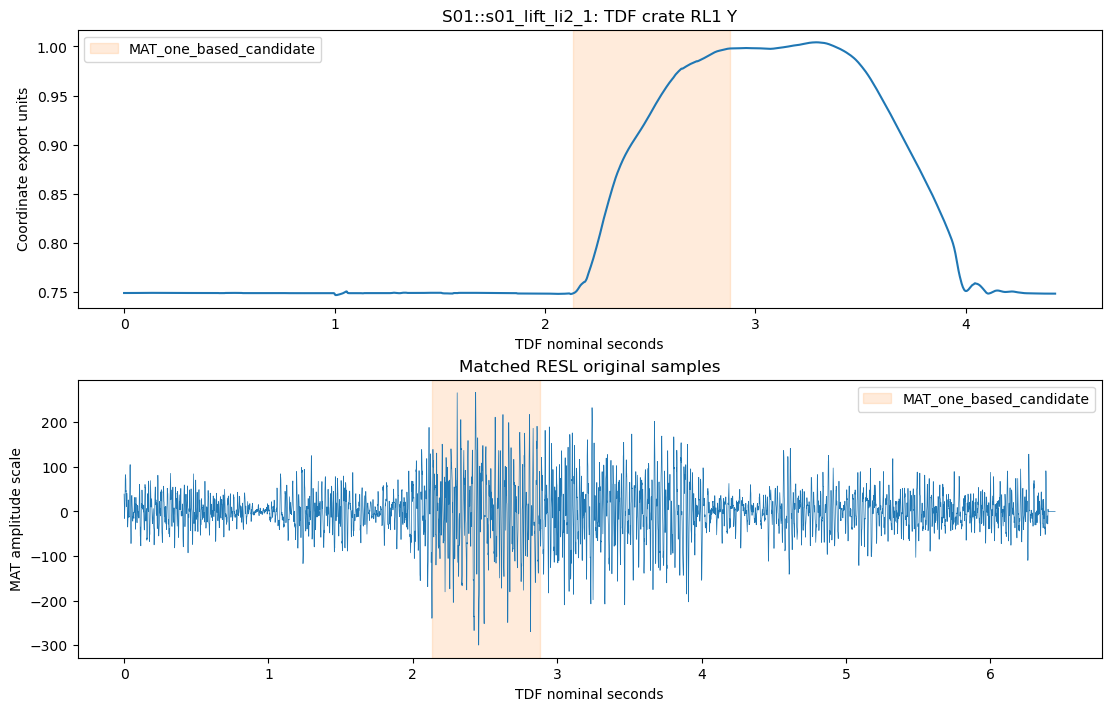

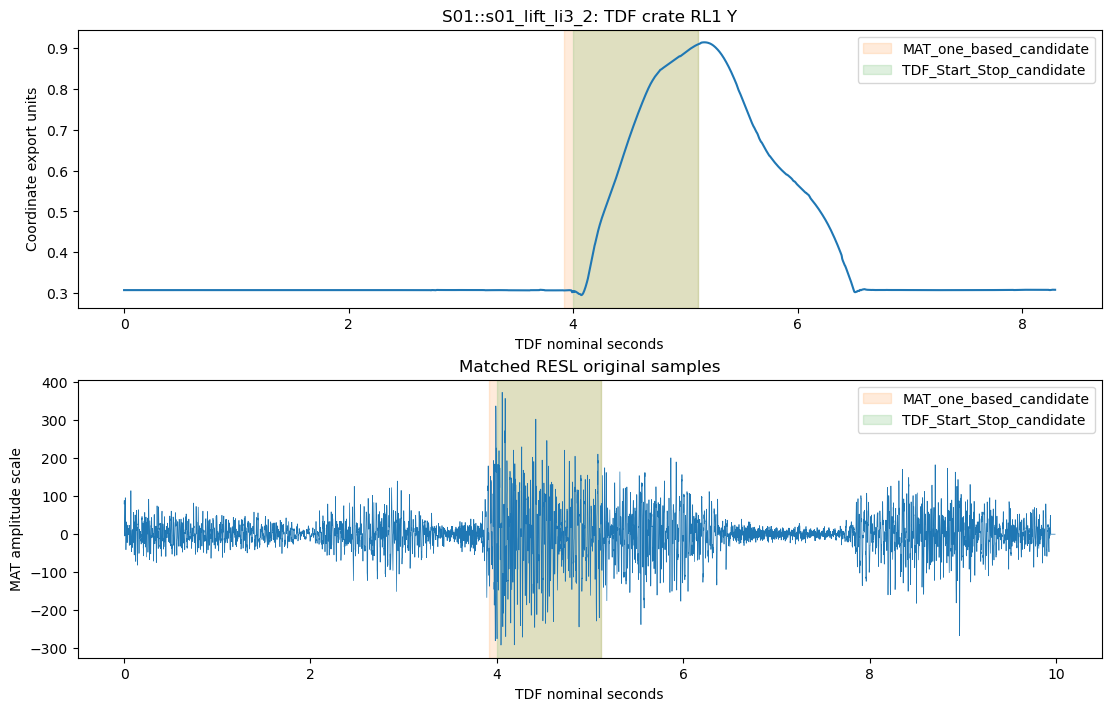

Trial failed S01::s01_lift_li3_3 Expected one TDF and EMG match, found 0 and 1
[2/17] S10
[3/17] S11
Trial failed S11::s11_lift_li1_1 Expected one TDF and EMG match, found 0 and 1
Trial failed S11::s11_lift_li1_2 Expected one TDF and EMG match, found 0 and 1
Trial failed S11::s11_lift_li1_3 Expected one TDF and EMG match, found 0 and 1
Trial failed S11::s11_lift_li2_1 Expected one TDF and EMG match, found 0 and 1
Trial failed S11::s11_lift_li2_2 Expected one TDF and EMG match, found 0 and 1
Trial failed S11::s11_lift_li2_3 Expected one TDF and EMG match, found 0 and 1
[4/17] S12
Trial failed S12::s12_lift_li1_1 Expected one TDF and EMG match, found 0 and 1
Trial failed S12::s12_lift_li1_2 Expected one TDF and EMG match, found 0 and 1
Trial failed S12::s12_lift_li1_3 Expected one TDF and EMG match, found 0 and 1
Trial failed S12::s12_lift_li2_1 Expected one TDF and EMG match, found 0 and 1
Trial failed S12::s12_lift_li2_2 Expected one TDF and EMG match, found 0 and 1
Trial failed S12::s

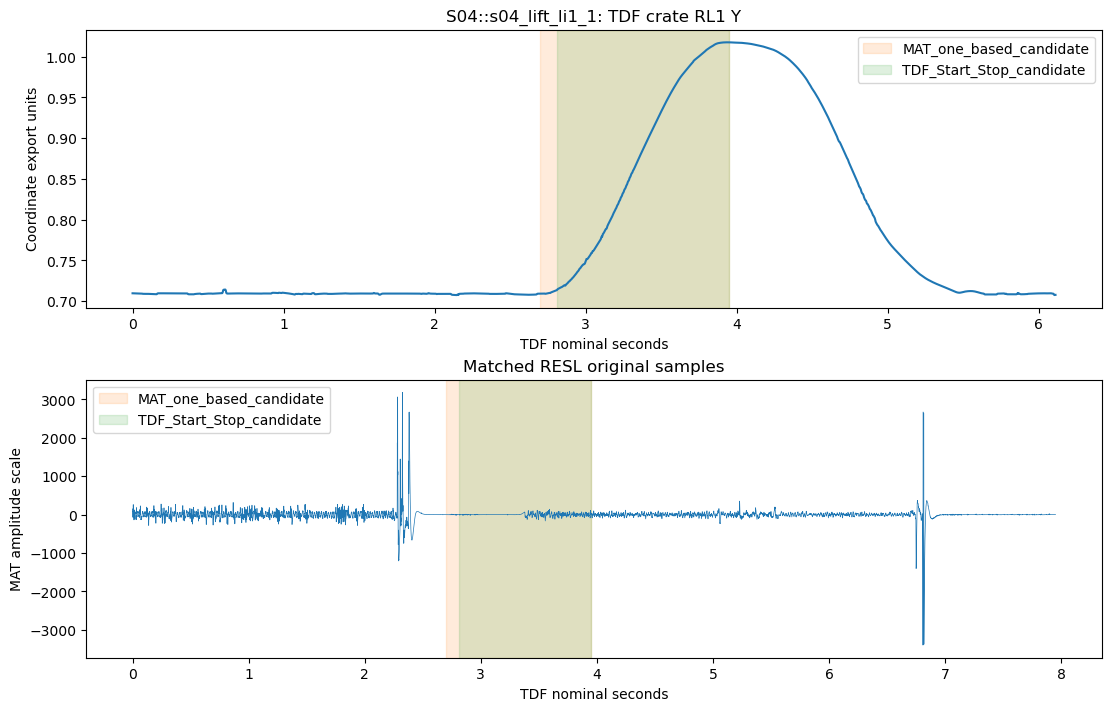

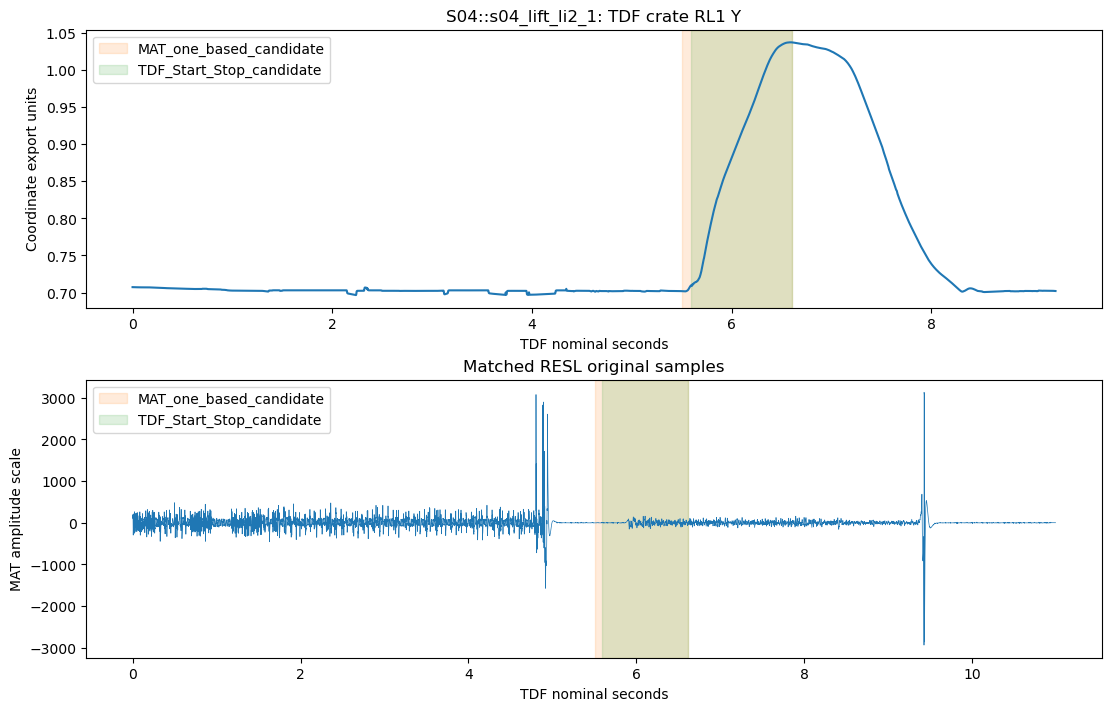

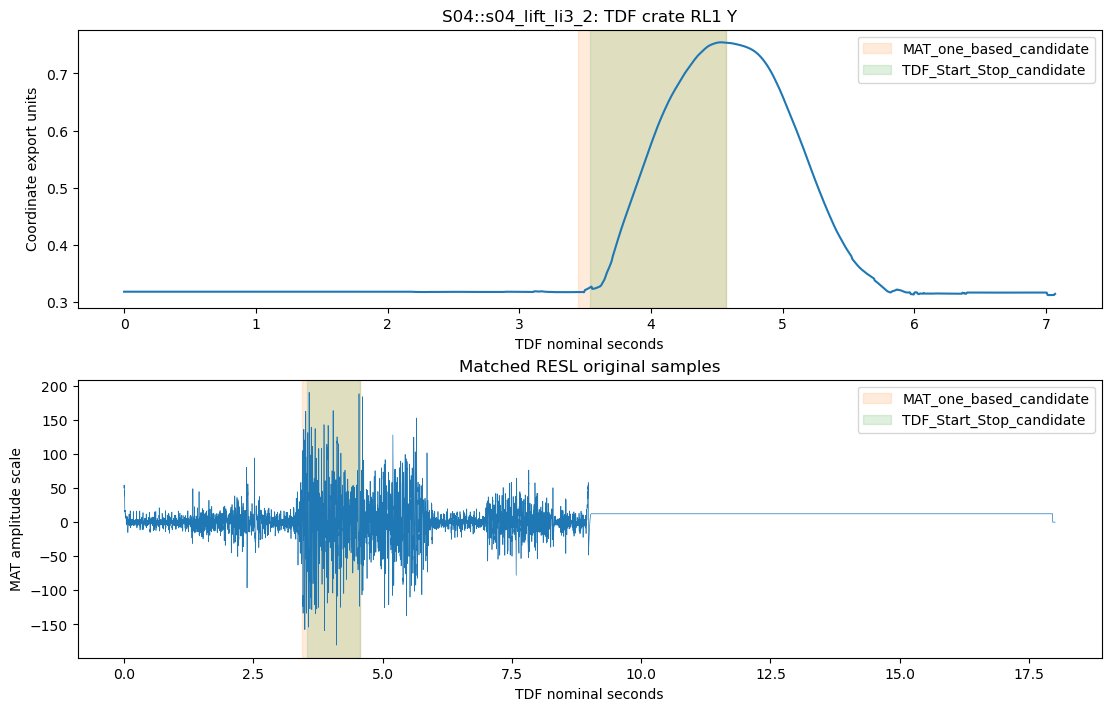

[13/17] S05
[14/17] S06
[15/17] S07
[16/17] S08
[17/17] S09


,subject,trial_id,LI,tdf_file,tdf_sha256,motion_start_s,emg_start_s,emg_elapsed_equals_motion_elapsed_plus_s,motion_fs,emg_fs,motion_samples,emg_declared_samples,unique_EMG_mappings,marker_correspondence_candidate,rates_agree,nominal_source_correspondence_supported,hardware_latency_verified,phase_definition_selected,TDF_Start_s,TDF_Stop_s
0,S01,S01::s01_lift_li1_1,1,S01/Proprietary/TDF_format/S01_Lift_LI1_1.TDF,ac1b0dc63aa8c8dc256368ece4690d660a2c3bb3f6849f...,0.0,0.0,0.0,340,1000,3227,11482,16,True,True,True,False,False,4.808824,6.464706
1,S01,S01::s01_lift_li1_2,1,S01/Proprietary/TDF_format/S01_Lift_LI1_2.TDF,853599199b278b3d64be6790c6ec176b511710ecb66e89...,0.0,0.0,0.0,340,1000,2472,8921,14,True,True,False,False,False,2.744118,3.747059
2,S01,S01::s01_lift_li1_3,1,S01/Proprietary/TDF_format/S01_Lift_LI1_3.TDF,3a27f0dda77c90dfdaa9bf432afd9a847a63e3c5319ee6...,0.0,0.0,0.0,340,1000,2472,8921,14,True,True,False,False,False,2.744118,3.747059
3,S01,S01::s01_lift_li2_1,2,S01/Proprietary/TDF_format/S01_Lift_LI2_1.TDF,2eed5700b9786fd0b96aab20cffbceb66675c84440af08...,0.0,0.0,0.0,340,1000,1505,6449,16,True,True,True,False,False,NaN,NaN
4,S01,S01::s01_lift_li2_2,2,S01/Proprietary/TDF_format/S01_Lift_LI2_2.TDF,586a4d6f00df0256868ce755a6e47fe7dbfd3b7cec8ee0...,0.0,0.0,0.0,340,1000,1914,7428,16,True,True,True,False,False,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
84,S09,S09::s09_lift_li2_2,2,S09/Proprietary/TDF_format/S09_Lift_LI2_2.TDF,f4bbf97df952545e7f7c8eee127cc5955d911c5fc93e3d...,0.0,0.0,0.0,340,1000,3105,10770,16,True,True,True,False,False,3.526471,4.964706
85,S09,S09::s09_lift_li2_3,2,S09/Proprietary/TDF_format/S09_Lift_LI2_3.TDF,03b8b69d42f5dabece0f364f709d7e92af7f980fb2e463...,0.0,0.0,0.0,340,1000,2713,9958,16,True,True,True,False,False,2.932353,4.300000
86,S09,S09::s09_lift_li3_1,3,S09/Proprietary/TDF_format/S09_Lift_LI3_1.TDF,0b2ba2448ec7c4600be04b0857c97b7411f517b12d6481...,0.0,0.0,0.0,340,1000,3167,10915,16,True,True,True,False,False,5.088235,6.573529
87,S09,S09::s09_lift_li3_2,3,S09/Proprietary/TDF_format/S09_Lift_LI3_2.TDF,5e8b14a14f7dd893badf894c339f76df56837651d0b2e9...,0.0,0.0,0.0,340,1000,2716,9948,16,True,True,True,False,False,2.961765,4.252941


,subject,trial_id,error,traceback
0,S01,S01::s01_lift_li3_3,"Expected one TDF and EMG match, found 0 and 1","Traceback (most recent call last):\n File ""/t..."
1,S11,S11::s11_lift_li1_1,"Expected one TDF and EMG match, found 0 and 1","Traceback (most recent call last):\n File ""/t..."
2,S11,S11::s11_lift_li1_2,"Expected one TDF and EMG match, found 0 and 1","Traceback (most recent call last):\n File ""/t..."
3,S11,S11::s11_lift_li1_3,"Expected one TDF and EMG match, found 0 and 1","Traceback (most recent call last):\n File ""/t..."
4,S11,S11::s11_lift_li2_1,"Expected one TDF and EMG match, found 0 and 1","Traceback (most recent call last):\n File ""/t..."
...,...,...,...,...
38,S17,S17::s17_lift_li1_2,"Expected one TDF and EMG match, found 0 and 1","Traceback (most recent call last):\n File ""/t..."
39,S17,S17::s17_lift_li1_3,"Expected one TDF and EMG match, found 0 and 1","Traceback (most recent call last):\n File ""/t..."
40,S17,S17::s17_lift_li2_1,"Expected one TDF and EMG match, found 0 and 1","Traceback (most recent call last):\n File ""/t..."
41,S17,S17::s17_lift_li2_2,"Expected one TDF and EMG match, found 0 and 1","Traceback (most recent call last):\n File ""/t..."


In [5]:
trial_rows, track_rows, marker_rows, map_rows, event_rows, phase_rows, hash_rows, failures, block_rows = [], [], [], [], [], [], [], [], []
plot_count=0
marker_map={"c7":"c7","load_RL1":"RL1","load_RL2":"RL2","load_LL1":"LL1","load_LL2":"LL2"}
for number,path in enumerate(mat_paths,1):
    sid=sid_from(path.name)
    print(f"[{number}/{len(mat_paths)}] {sid}",flush=True)
    try:
        raw=loadmat(path,simplify_cells=True)
        roots=[v for k,v in raw.items() if not k.startswith("__") and isinstance(v,dict) and "Kinematic_data" in v]
        if len(roots)!=1:
            raise ValueError("Ambiguous MATLAB root")
        data=roots[0]
        emg_index=defaultdict(list)
        for rec in entries(data.get("sEMG")):
            emg_index[task_key(rec.get("task",""))].append(rec)
        for k in entries(data.get("Kinematic_data")):
            task=task_key(k.get("task",""))
            tid=sid+"::"+task
            try:
                matches=tdf_index.get((sid,task),[])
                ematches=emg_index.get(task,[])
                if len(matches)!=1 or len(ematches)!=1:
                    raise ValueError(f"Expected one TDF and EMG match, found {len(matches)} and {len(ematches)}")
                e=ematches[0]
                source=parse_tdf(matches[0])
                if 5 not in source["blocks"] or 11 not in source["blocks"]:
                    raise ValueError("TDF lacks required movement or EMG block")
                motion,emg=source["blocks"][5],source["blocks"][11]
                evblock=source["blocks"].get(16,{"start":0.0,"events":[]})
                fm,fe=motion["frequency"],emg["frequency"]
                for b in source["entries"]:
                    block_rows.append({"subject":sid,"trial_id":tid,**b})
                for group,payload in [("motion",k.get("data_3D",{})),("emg",e.get("data_sEMG",{}))]:
                    hash_rows.append({"subject":sid,"trial_id":tid,"group":group,"sha256":digest(payload)})
                track_index=defaultdict(list)
                for tr in motion["tracks"]:
                    track_index[tr["label"]].append(tr)
                local_markers=[]
                for mat_name,label in marker_map.items():
                    a=np.asarray(k.get("data_3D",{}).get(mat_name,[]))
                    match=track_index.get(label,[])
                    exact_shape=len(match)==1 and a.shape==match[0]["data"].shape
                    err=a.astype(float)-match[0]["data"].astype(float) if exact_shape else np.array([np.nan])
                    finite=bool(exact_shape and np.isfinite(err).all())
                    rmse=float(np.sqrt(np.mean(err**2))) if finite else np.nan
                    maxerr=float(np.max(np.abs(err))) if finite else np.nan
                    row={"subject":sid,"trial_id":tid,"mat_marker":mat_name,"tdf_label":label,"same_shape":exact_shape,"finite_comparison":finite,"rmse_export_units":rmse,"max_abs_error_export_units":maxerr,"within_engineering_review_limits":bool(finite and rmse<=MARKER_RMSE_REVIEW_LIMIT and maxerr<=MARKER_MAX_ERROR_REVIEW_LIMIT)}
                    marker_rows.append(row)
                    local_markers.append(row)
                for index,tr in enumerate(emg["tracks"]):
                    a=tr["data"]
                    runs=constant_runs(a)
                    longest=max(runs,key=lambda x:x[1]-x[0]) if runs else (0,0,np.nan)
                    track_rows.append({"subject":sid,"trial_id":tid,"track_index":index,"label":tr["label"],"samples":len(a),"segments":json.dumps(tr["segments"]),"finite_fraction":float(np.isfinite(a).mean()),"longest_constant_start_s":emg["start"]+longest[0]/fe,"longest_constant_end_s":emg["start"]+longest[1]/fe,"longest_constant_seconds":(longest[1]-longest[0])/fe,"longest_constant_value":longest[2]})
                chosen={}
                for channel in EXPECTED_EMG:
                    a=np.asarray(e.get("data_sEMG",{}).get(channel,[]),dtype=float).reshape(-1)
                    candidates=[]
                    for j,tr in enumerate(emg["tracks"]):
                        b=tr["data"]
                        if len(a)==len(b) and len(a)>0 and np.isfinite(a).all() and np.isfinite(b).all():
                            err=float(np.max(np.abs(a-b.astype(float)*1e6)))
                            if err<=1e-8:
                                candidates.append((j,tr["label"],err))
                    row={"subject":sid,"trial_id":tid,"mat_channel":channel,"match_count":len(candidates),"matching_indices":json.dumps([x[0] for x in candidates]),"matching_labels":json.dumps([x[1] for x in candidates]),"max_error_after_1e6_scale":candidates[0][2] if len(candidates)==1 else np.nan,"unique_match":len(candidates)==1}
                    map_rows.append(row)
                    if len(candidates)==1:
                        chosen[channel]=emg["tracks"][candidates[0][0]]
                mev={name:scalar(value) for name,value in k.get("events",{}).items()}
                tev=[]
                for event in evblock["events"]:
                    for value in event["values"]:
                        tev.append((event["label"],float(value)+evblock["start"]))
                for name,index in mev.items():
                    for label,time in tev:
                        for base in [0,1]:
                            candidate_time=motion["start"]+(index-base)/fm
                            event_rows.append({"subject":sid,"trial_id":tid,"mat_event":name,"mat_index":index,"index_base":base,"mat_time_on_nominal_clock_s":candidate_time,"tdf_event":label,"tdf_time_s":time,"difference_s":candidate_time-time})
                start_events=[time for name,time in tev if name.strip().lower()=="start"]
                stop_events=[time for name,time in tev if name.strip().lower()=="stop"]
                phases=[]
                if all(np.isfinite(mev.get(name,np.nan)) for name in ["start","stop"]):
                    phases.append(("MAT_one_based_candidate",motion["start"]+(mev["start"]-1)/fm,motion["start"]+(mev["stop"]-1)/fm))
                if len(start_events)==1 and len(stop_events)==1:
                    phases.append(("TDF_Start_Stop_candidate",start_events[0],stop_events[0]))
                rates_agree=fm==scalar(k.get("fs_3D")) and fe==scalar(e.get("fs_sEMG"))
                marker_support=all(x["within_engineering_review_limits"] for x in local_markers)
                correspondence=bool(rates_agree and len(chosen)==16 and marker_support)
                nominal_offset=motion["start"]-emg["start"]
                li_match=re.search(r"LI(\d+)",task,re.I)
                trial_rows.append({"subject":sid,"trial_id":tid,"LI":int(li_match.group(1)) if li_match else None,"tdf_file":str(matches[0].relative_to(DATA_ROOT)),"tdf_sha256":source["sha256"],"motion_start_s":motion["start"],"emg_start_s":emg["start"],"emg_elapsed_equals_motion_elapsed_plus_s":nominal_offset,"motion_fs":fm,"emg_fs":fe,"motion_samples":motion["count"],"emg_declared_samples":emg["count"],"unique_EMG_mappings":len(chosen),"marker_correspondence_candidate":marker_support,"rates_agree":rates_agree,"nominal_source_correspondence_supported":correspondence,"hardware_latency_verified":False,"phase_definition_selected":False,"TDF_Start_s":start_events[0] if len(start_events)==1 else np.nan,"TDF_Stop_s":stop_events[0] if len(stop_events)==1 else np.nan})
                for phase,t0,t1 in phases:
                    i0=int(np.ceil((t0-emg["start"])*fe-1e-5))
                    i1=int(np.ceil((t1-emg["start"])*fe-1e-5))
                    interval=bool(np.isfinite([t0,t1]).all() and t0<t1 and 0<=i0<i1<=emg["count"] and t0>=motion["start"] and t1<=motion["start"]+motion["count"]/fm)
                    for channel in EXPECTED_EMG:
                        tr=chosen.get(channel)
                        metrics=phase_stats(tr["data"],fe,i0,i1) if tr is not None and interval else {"samples":0,"finite_fraction":0.0,"longest_constant_s":np.nan,"zero_fraction":np.nan,"raw_rms":np.nan}
                        qc=bool(interval and correspondence and tr is not None and metrics["finite_fraction"]==1 and metrics["longest_constant_s"]<CONSTANT_RUN_REVIEW_SECONDS and metrics["raw_rms"]>0)
                        phase_rows.append({"subject":sid,"trial_id":tid,"phase_definition":phase,"channel":channel,"phase_start_s":t0,"phase_stop_s":t1,"emg_start_index":i0,"emg_stop_exclusive":i1,"interval_in_bounds":interval,**metrics,"candidate_phase_qc_pass":qc,"filtered_phase_rms_in_mat_scale":phase_filtered_rms(tr["data"],fe,i0,i1)*1e6 if qc else np.nan,"endpoint_approved":False})
                if plot_count<MAX_FIGURES and (sid in ["S01","S04","S12","S16"]) and (task.endswith('li1_1') or task.endswith('li3_2') or task.endswith('li2_1')):
                    fig,axes=plt.subplots(2,1,figsize=(11,7),constrained_layout=True)
                    crate=track_index.get("RL1",[])
                    if len(crate)==1:
                        axes[0].plot(motion["start"]+np.arange(motion["count"])/fm,crate[0]["data"][:,1])
                    if "RESL" in chosen:
                        a=chosen["RESL"]["data"]
                        axes[1].plot(emg["start"]+np.arange(len(a))/fe,a*1e6,linewidth=0.5)
                    for phase,t0,t1 in phases:
                        color="tab:orange" if phase.startswith("MAT") else "tab:green"
                        for ax in axes:
                            ax.axvspan(t0,t1,color=color,alpha=0.15,label=phase)
                            ax.legend()
                    axes[0].set(title=tid+": TDF crate RL1 Y",ylabel="Coordinate export units",xlabel="TDF nominal seconds")
                    axes[1].set(title="Matched RESL original samples",ylabel="MAT amplitude scale",xlabel="TDF nominal seconds")
                    p=FIG_DIR/(task+".png")
                    fig.savefig(p,dpi=120)
                    plt.show()
                    plt.close(fig)
                    plot_count+=1
            except Exception as exc:
                failures.append({"subject":sid,"trial_id":tid,"error":str(exc),"traceback":traceback.format_exc()})
                print("Trial failed",tid,str(exc))
        del raw,data
    except Exception as exc:
        failures.append({"subject":sid,"file":str(path),"error":str(exc),"traceback":traceback.format_exc()})
trials=pd.DataFrame(trial_rows)
phases=pd.DataFrame(phase_rows)
tracks=pd.DataFrame(track_rows)
mappings=pd.DataFrame(map_rows)
markers=pd.DataFrame(marker_rows)
events=pd.DataFrame(event_rows)
hashes=pd.DataFrame(hash_rows)
if trials.empty:
    (RUN_DIR/"errors.json").write_text(json.dumps(failures,indent=2))
    raise RuntimeError(f"No trials parsed. Inspect {RUN_DIR}")
display(trials)
display(pd.DataFrame(failures))

## Duplicate and phase provenance ledger
Cross-participant duplicate source arrays remain quarantined. Within-participant duplicates receive a deterministic candidate representative; conflicting MATLAB annotations hold the family for review. These flags are computed from current MATLAB arrays without requiring a previous audit ZIP. Candidate counts do not establish endpoint validity or publication readiness.

In [6]:
dups=[]
for (group,fingerprint),frame in hashes.dropna(subset=["sha256"]).groupby(["group","sha256"]):
    if len(frame)>1:
        for row in frame.to_dict("records"):
            dups.append(dict(row,family=group+"_"+fingerprint[:16],cross_subject=frame.subject.nunique()>1))
duplicates=pd.DataFrame(dups,columns=list(hashes.columns)+["family","cross_subject"])
trials["cross_subject_quarantine"]=False
trials["duplicate_nonrepresentative"]=False
trials["duplicate_phase_conflict"]=False
for family,frame in duplicates.groupby("family"):
    ids=sorted(frame.trial_id.unique())
    affected=trials.trial_id.isin(ids)
    if frame.cross_subject.any():
        trials.loc[affected,"cross_subject_quarantine"]=True
    else:
        trials.loc[trials.trial_id.isin(ids[1:]),"duplicate_nonrepresentative"]=True
        p=phases[phases.trial_id.isin(ids)]
        unique_intervals=p[["trial_id","phase_definition","phase_start_s","phase_stop_s"]].drop_duplicates()
        for phase,f in unique_intervals.groupby("phase_definition"):
            if len(f[["phase_start_s","phase_stop_s"]].drop_duplicates())>1:
                trials.loc[affected,"duplicate_phase_conflict"]=True
trials["primary_cohort_candidate"]=trials.LI.isin([1,2])
trials["secondary_cohort_candidate"]=trials.subject.isin([f"S{i:02d}" for i in range(1,11)]) & trials.LI.isin([1,2,3])
phases=phases.merge(trials[["trial_id","cross_subject_quarantine","duplicate_nonrepresentative","duplicate_phase_conflict","primary_cohort_candidate","secondary_cohort_candidate"]],on="trial_id",validate="many_to_one",how="left")
phases["candidate_after_provenance_checks"]=phases.candidate_phase_qc_pass & ~phases.cross_subject_quarantine & ~phases.duplicate_nonrepresentative & ~phases.duplicate_phase_conflict
phases["training_ready"]=False
display(duplicates)
display(phases.groupby("phase_definition").agg(channel_rows=("channel","size"),phase_qc_pass=("candidate_phase_qc_pass","sum"),after_provenance=("candidate_after_provenance_checks","sum")))
display(events[(events.mat_event=="stop") & (events.tdf_event.str.lower()=="stop")].groupby("index_base").difference_s.describe())
display(events[(events.mat_event=="start") & (events.tdf_event.str.lower()=="start")].groupby("index_base").difference_s.describe())
display(tracks.sort_values("longest_constant_seconds",ascending=False).head(20))

,subject,trial_id,group,sha256,family,cross_subject
0,S09,S09::s09_lift_li3_2,emg,73d6873bfe9257f1fbb068facd12845b0eac17a6004eb2...,emg_73d6873bfe9257f1,False
1,S09,S09::s09_lift_li3_3,emg,73d6873bfe9257f1fbb068facd12845b0eac17a6004eb2...,emg_73d6873bfe9257f1,False
2,S01,S01::s01_lift_li1_2,emg,a0245510228114040e7bacfe343917048f99a8a3ff8987...,emg_a024551022811404,False
3,S01,S01::s01_lift_li1_3,emg,a0245510228114040e7bacfe343917048f99a8a3ff8987...,emg_a024551022811404,False
4,S04,S04::s04_lift_li3_2,emg,af029a5c1fd2917fc208c0ad2e0217a97bcb781c7f075c...,emg_af029a5c1fd2917f,False
5,S04,S04::s04_lift_li3_3,emg,af029a5c1fd2917fc208c0ad2e0217a97bcb781c7f075c...,emg_af029a5c1fd2917f,False
6,S05,S05::s05_lift_li3_2,emg,cba12c991fca50d750b2cb94f026f53374868fd1ac156e...,emg_cba12c991fca50d7,False
7,S05,S05::s05_lift_li3_3,emg,cba12c991fca50d750b2cb94f026f53374868fd1ac156e...,emg_cba12c991fca50d7,False
8,S01,S01::s01_lift_li1_2,motion,13501669b9d1481b27fbd90c4e3e66a7a644e1915c6121...,motion_13501669b9d1481b,False
9,S01,S01::s01_lift_li1_3,motion,13501669b9d1481b27fbd90c4e3e66a7a644e1915c6121...,motion_13501669b9d1481b,False


,channel_rows,phase_qc_pass,after_provenance
phase_definition,,,
MAT_one_based_candidate,1424,898,866
TDF_Start_Stop_candidate,1168,747,715


,count,mean,std,min,25%,50%,75%,max
index_base,,,,,,,,
0,73.0,0.009428,0.040318,2.940946e-03,2.941104e-03,2.941196e-03,2.941249e-03,0.302941
1,73.0,0.006487,0.040318,-2.300038e-07,-7.292804e-08,1.963447e-08,7.292804e-08,0.300000


,count,mean,std,min,25%,50%,75%,max
index_base,,,,,,,,
0,73.0,-0.140854,0.093041,-0.417647,-0.173529,-0.126471,-0.094118,0.220588
1,73.0,-0.143795,0.093041,-0.420588,-0.176471,-0.129412,-0.097059,0.217647


,subject,trial_id,track_index,label,samples,segments,finite_fraction,longest_constant_start_s,longest_constant_end_s,longest_constant_seconds,longest_constant_value
1191,S04,S04::s04_lift_li3_2,15,Left Obliquus internus abdominis,18006,"[[0, 18006]]",1.0,6.787,17.957,11.170,9.496150e-06
1219,S04,S04::s04_lift_li3_3,15,Left Obliquus internus abdominis,18006,"[[0, 18006]]",1.0,6.787,17.957,11.170,9.496150e-06
1066,S04,S04::s04_lift_li2_1,2,Right Multifidus,10991,"[[0, 10991]]",1.0,0.050,10.942,10.892,5.229595e-12
183,S01,S01::s01_lift_li3_1,15,Left Obliquus internus abdominis,10990,"[[0, 10990]]",1.0,0.050,10.941,10.891,5.229595e-12
1215,S04,S04::s04_lift_li3_3,11,Left Latissimus Dorsi,18006,"[[0, 18006]]",1.0,7.289,17.957,10.668,1.427581e-05
1187,S04,S04::s04_lift_li3_2,11,Left Latissimus Dorsi,18006,"[[0, 18006]]",1.0,7.289,17.957,10.668,1.427581e-05
1078,S04,S04::s04_lift_li2_1,14,Left Obliquus externus abdominis,10991,"[[0, 10991]]",1.0,0.363,10.942,10.579,4.861196e-06
1178,S04,S04::s04_lift_li3_2,2,Right Multifidus,18006,"[[0, 18006]]",1.0,8.107,17.957,9.850,1.591366e-05
1206,S04,S04::s04_lift_li3_3,2,Right Multifidus,18006,"[[0, 18006]]",1.0,8.107,17.957,9.850,1.591366e-05
1179,S04,S04::s04_lift_li3_2,3,Right Latissimus Dorsi,18006,"[[0, 18006]]",1.0,8.355,17.957,9.602,2.175373e-05


## Export results and next decision
V3 distinguishes nominal metadata support, signal correspondence, phase QC and endpoint approval. No training-ready flag is set automatically. Next, review global event comparisons, choose a reproducible movement-based phase definition, review MVC normalization and report usable independent workers. A mismatch is an investigation result, not permission to optimize time offsets against EMG outcomes. INAIL 2 remains an external-extension question.

In [7]:
def json_clean(x):
    if isinstance(x,dict):
        return {str(k):json_clean(v) for k,v in x.items()}
    if isinstance(x,(list,tuple)):
        return [json_clean(v) for v in x]
    if isinstance(x,np.generic):
        return json_clean(x.item())
    if isinstance(x,float) and not np.isfinite(x):
        return None
    return x

def save_json(name,value):
    (RUN_DIR/name).write_text(json.dumps(json_clean(value),indent=2,ensure_ascii=False,allow_nan=False),encoding="utf-8")

summary={"version":"3.0","project_root":str(PROJECT_ROOT),"data_root":str(DATA_ROOT),"MAT_files":len(mat_paths),"TDF_files":len(tdf_paths),"parsed_trial_rows":len(trials),"parsed_participants":int(trials.subject.nunique()),"errors":len(failures),"nominal_source_correspondence_supported_trials":int(trials.nominal_source_correspondence_supported.sum()),"cross_subject_quarantined_trials":int(trials.cross_subject_quarantine.sum()),"candidate_phase_channel_rows":len(phases),"candidate_phase_channel_rows_after_provenance":int(phases.candidate_after_provenance_checks.sum()),"approved_training_rows":0,"hardware_latency_verified":False,"phase_definition_selected":False,"MVC_normalization_applied":False,"INAIL2":"Optional extension; does not repair source provenance or event-definition problems.","next_step":"Review event reconciliation and phase QC, fix the phase definition and MVC rules, then construct reviewed targets."}
tables={"trial_timing_ledger":trials,"candidate_phase_channel_ledger":phases,"EMG_track_inventory":tracks,"MAT_TDF_channel_mapping":mappings,"marker_correspondence":markers,"event_reconciliation":events,"duplicate_provenance":duplicates,"MAT_stream_hashes":hashes,"TDF_block_directory":pd.DataFrame(block_rows)}
for name,frame in tables.items():
    if not len(frame.columns):
        frame=pd.DataFrame(columns=["no_records"])
    frame.to_csv(RUN_DIR/f"{name}.csv",index=False)
    save_json(f"{name}.json",frame.to_dict("records"))
save_json("errors.json",failures)
save_json("audit_summary.json",summary)
save_json("configuration.json",{"marker_rmse_review_limit":MARKER_RMSE_REVIEW_LIMIT,"marker_max_error_review_limit":MARKER_MAX_ERROR_REVIEW_LIMIT,"constant_run_review_seconds":CONSTANT_RUN_REVIEW_SECONDS,"source_mapping_scale":1e6,"EMG_matching_tolerance":1e-8,"phase_definitions":["MAT_one_based_candidate","TDF_Start_Stop_candidate"],"parser":"bounded_version1_by_track_no_sample_count_adjustment","python":sys.version,"numpy":np.__version__,"pandas":pd.__version__})
(RUN_DIR/"READ_ME_FIRST.txt").write_text("Project A INAIL1 TDF V3\n\n"+json.dumps(summary,indent=2)+"\n\nNo training performed. Candidate phase values are diagnostics on TDF nominal clocks. Inspect errors, channel mapping, marker correspondence and duplicate provenance before interpreting pooled counts. Both phase definitions are reported separately; neither has been selected automatically. Missing data and constant runs are flagged. Source files remain unchanged. No raw recordings are included in the ZIP.",encoding="utf-8")
archive_dir=PROJECT_ROOT/"archives"
archive_dir.mkdir(parents=True,exist_ok=True)
zip_path=archive_dir/f"ProjectA_INAIL1_TDF_V3_{RUN_DIR.name}.zip"
with zipfile.ZipFile(zip_path,"w",zipfile.ZIP_DEFLATED) as archive:
    for p in sorted(RUN_DIR.rglob("*")):
        if p.is_file():
            archive.write(p,str(p.relative_to(RUN_DIR)))
print(json.dumps(summary,indent=2))
print("V3 COMPLETE")
print("Upload ZIP:",zip_path)
print("Save and upload the executed notebook as well.")

{
  "version": "3.0",
  "project_root": "/home/rafsan/Documents/GitHub/IPEXBIO/Project_A",
  "data_root": "/home/rafsan/Downloads/INAIL_1/Dataset1/DATA",
  "MAT_files": 17,
  "TDF_files": 132,
  "parsed_trial_rows": 89,
  "parsed_participants": 10,
  "errors": 43,
  "nominal_source_correspondence_supported_trials": 58,
  "cross_subject_quarantined_trials": 0,
  "candidate_phase_channel_rows": 2592,
  "candidate_phase_channel_rows_after_provenance": 1581,
  "approved_training_rows": 0,
  "hardware_latency_verified": false,
  "phase_definition_selected": false,
  "MVC_normalization_applied": false,
  "INAIL2": "Optional extension; does not repair source provenance or event-definition problems.",
  "next_step": "Review event reconciliation and phase QC, fix the phase definition and MVC rules, then construct reviewed targets."
}
V3 COMPLETE
Upload ZIP: /home/rafsan/Documents/GitHub/IPEXBIO/Project_A/archives/ProjectA_INAIL1_TDF_V3_run_20261113T055107_741782Z.zip
Save and upload the execute